## Connections and Pore Windows 


*Note: These tutorials are not a substitute for reading the paper. For details on the algorithms working under the hood, please read the original publication. However, these tutorials are useful for learning the syntax of mofography*

In this tutorial, we will learn how to find the connections between the different cavities in a material, locate the one or more adjoining pore windows, and to finally visualize them along with everything else that we have seen so far.

Finding the pore windows is an involved calculation, hence we need everything we have computed so far to get the pore windows, we need
- The distance grid
- the local maxima of the distance grid
- the region segmentation grid
- the distance values at the local maxima
- the pore graph

To give some brief insights into the window finding algorithm in mofography, we locate the windows as the centroid of the points in the shared outer boundary of two touching regions. There are couple of nuances to window finding,

- The windows can be fully internal to the unit cell or across periodic boundaries, mofography can detect and distinguich both of these.
- There can be multiple windows between two touching regions, mofography can detect these as long as these windows are spatially separated by at least 1 Å. Under the hood, mofography uses agglomerative clustering to group the boundary points before taking the centroid to account for this.


As before, we won't be explaining the steps that we have already covered in the previous tutorials, if anything is unclear, please refer to the previous tutorials. 



## Imports

In [1]:
import sys, os 
path_to_mgr = os.path.abspath('c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography')
sys.path.append(path_to_mgr)
import mofography as mgr 


## Read in the structure 

In [2]:
from ase.io import read 
path_to_cif=os.path.join(path_to_mgr,'examples', 'TestCIFs','P1-IRMOF-1.cif')
mat_atoms = read(path_to_cif)
mat_updated = mgr.update_with_covalent_bonds(mat_atoms)


c:\Users\Public\anaconda3\envs\jl_env\lib\site-packages\ase\io\cif.py:401: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(


## Compute the distance grid

In [3]:
dgrid = mgr.dgrid_from_atoms(mat_atoms, spacing=0.5)

## Region segmenation

In [4]:
regions, maxima = mgr.regions_from_dgrid(dgrid.compute())

c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography\mofography\compute.py:327: UserWarning: Some maxima excluded as they fell inside the mask_thickness
  warnings.warn('Some maxima excluded as they fell inside the mask_thickness')


## Get the radii of the maxima


In [5]:
maxima_radii = dgrid.compute()[tuple(maxima.T)]

## Region adjacency graph

In [6]:
rag  = mgr.get_rag_from_regions_and_grid(regions, dgrid.compute(), mat_atoms, maxima=maxima)

## Get the windows and connections

We have seen all the steps so far. Once we have the pore graph, we can locate the windows between all the connected regions using mofography 

In [7]:
connections = mgr.get_connections_for_rag(rag, region_labels=regions, ase_atoms=mat_atoms, maxima=maxima, dgrid=dgrid.compute())

Now let's take a look at this connections variable.

In [8]:
connections

[array([(1, 2), True, 'internal',
        array([[1.41760976, 1.41760976, 7.32431707]]), array([2.47655993])],
       dtype=object),
 array([(1, 4), True, 'internal',
        array([[1.41760976, 7.32431707, 1.41760976]]), array([2.47655993])],
       dtype=object),
 array([(1, 10), True, 'internal',
        array([[7.32431707, 1.41760976, 1.41760976]]), array([2.47655993])],
       dtype=object),
 array([(2, 3), True, 'internal',
        array([[ 1.41760976,  1.41760976, 18.0109137 ]]),
        array([2.44982734])], dtype=object),
 array([(2, 5), True, 'internal',
        array([[ 1.37566864,  5.71284615, 12.66761538]]),
        array([2.41254168])], dtype=object),
 array([(2, 11), True, 'internal',
        array([[ 5.71284615,  1.37566864, 12.66761538]]),
        array([2.41254168])], dtype=object),
 array([(3, 6), True, 'internal',
        array([[ 1.41760976,  7.32431707, 23.91762101]]),
        array([1.98217015])], dtype=object),
 array([(3, 12), True, 'internal',
        array([[

The 'connections' variable is a list of lists. Each entry in has 4 elements.
- The labels of the two regions that are connected
- Confirmation flag
- Nature of the windows, whether it is internal or across periodic boundaries
- The coordinates of the window(s)
- The radius of the window in Å

## Visualize the windows

It is very useful to visualize the windows along with all the other information that we have already seen so far. Let's start by creating plot traces for the 
- framework
- the distance grid isosurface (colored by the regions)
- the local maxima
- the pore graph

In [9]:
import plotly.graph_objects as go
import plotly.express as px
cscale  = px.colors.qualitative.Pastel_r

frame_trace = mgr.plot_framework_as_mesh(mat_updated, stylize=True)
cell_trace = mgr.plot_cell(mat_updated)
isosurface_trace =  mgr.plot_surface_dgrid(dgrid.compute(), isovalue=1.75, ase_atoms  = mat_updated, opacity=0.7, region_labels=regions, cscale=cscale)
maxima_trace = mgr.plot_maxima(dgrid.compute(), maxima,mat_updated)
rag_trace = mgr.plot_rag(rag, name='pore graph')

c:\Users\Public\anaconda3\envs\jl_env\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning: Use get_global_number_of_atoms() instead
  warnings.warn('Use get_global_number_of_atoms() instead',


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography\mofography\visualize.py:763: UserWarning: Optimal rotation is not uniquely or poorly defined for the given sets of vectors.
  r = R.align_vectors(ring_normal.reshape(-1, 3), np.array([0, 0, 1]).reshape(-1, 3))


mofography offers a wrapper function to plot the windwos from the connections variable

In [10]:
windows_trace = mgr.plot_windows(connections, marker_color='red')

Now let's visualize everything in one figure. As before please change 'renderer' to 'notebook_connected' if you'd like to see the interactive plot in the notebook. Use 'renderer='browser'' to open the plot in a browser tab.

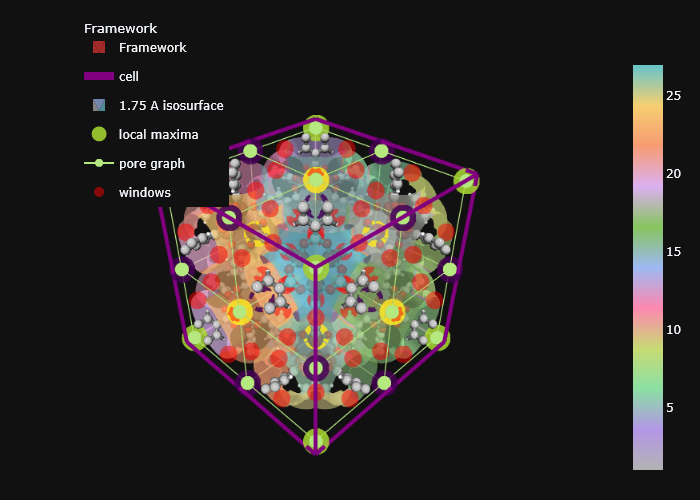

In [11]:
fig = go.Figure(data=[*frame_trace, cell_trace, isosurface_trace, maxima_trace, rag_trace, windows_trace])
fig.update(layout=mgr.dark_layout)
fig.show(renderer='png')

Hover the mouse over the scatter points marking the windows to see all the information about the windows.

## Where to go from here?

Detecting windows is somewhat of a branch off of the main mofography workflow. Feel free to check out the Pockets detection tutorial if you haven't already. The tutorial on Paths detection is also another solid option. You may also want to check out the rest of the advanced tutorials.